In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import mean, median, variance, stdev
from src.fish_stock import FishStock, PriceModel, RiskAssessor

In [2]:
fibonacci_stock = [0, 1]

for i in range(2, 15):
    next_number = fibonacci_stock[i - 1] + fibonacci_stock[i - 2]
    fibonacci_stock.append(next_number)

print("Fibonacci stock baseline:")
print(fibonacci_stock)

Fibonacci stock baseline:
[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]


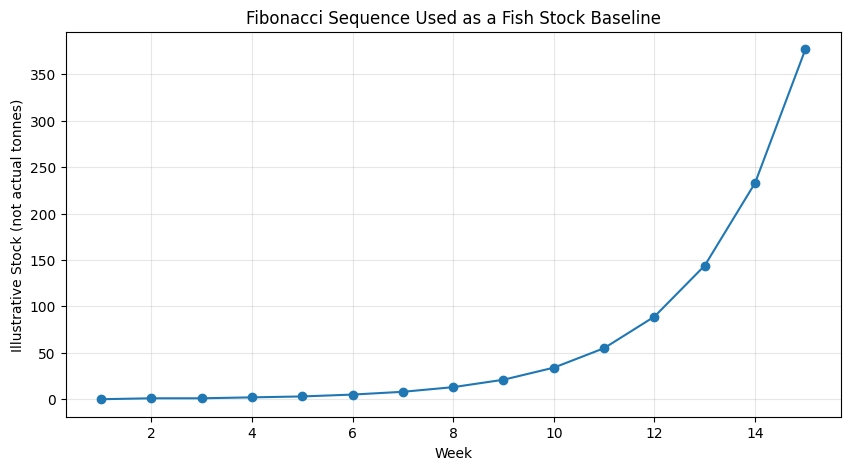

In [3]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 16),
    fibonacci_stock,
    marker="o"
)

plt.title("Fibonacci Sequence Used as a Fish Stock Baseline")
plt.xlabel("Week")
plt.ylabel("Illustrative Stock (not actual tonnes)")
plt.grid(True, alpha=0.3)

plt.show()

The Fibonacci sequence assumes that each new value is the sum of the two previous values, causing growth to accelerate without considering environmental conditions. Real fish populations are limited by factors such as food availability, habitat, competition, predation, and fishing pressure. As a population approaches the environment's carrying capacity, its growth rate generally slows rather than continuing to increase without limit. Therefore, Fibonacci numbers can serve as a simple mathematical baseline, but they are not a defensible model of fish stock dynamics.

In [4]:
fish_model = FishStock()

stock_52_weeks = fish_model.simulate(weeks=52)

print(f"Initial stock: {stock_52_weeks[0]:,.2f} tonnes")
print(f"Stock after 52 weeks: {stock_52_weeks[-1]:,.2f} tonnes")
print(f"Minimum stock: {stock_52_weeks.min():,.2f} tonnes")
print(f"Maximum stock: {stock_52_weeks.max():,.2f} tonnes")

Initial stock: 4,000.00 tonnes
Stock after 52 weeks: 7,500.00 tonnes
Minimum stock: 4,000.00 tonnes
Maximum stock: 7,500.00 tonnes


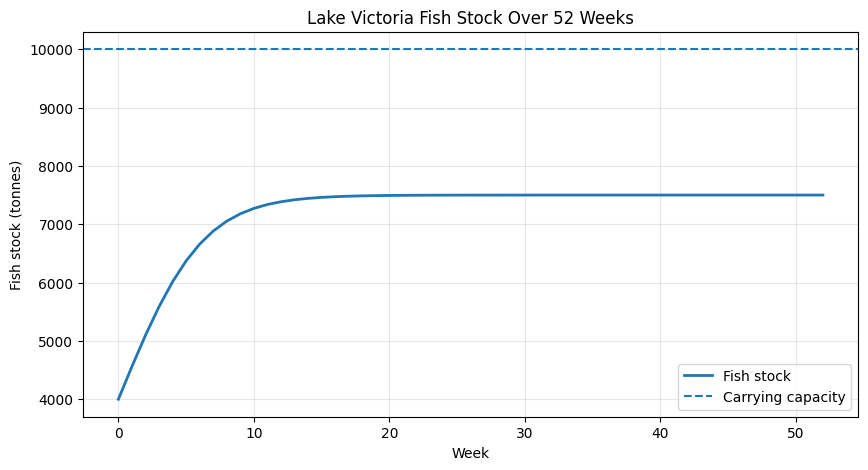

In [5]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(stock_52_weeks)),
    stock_52_weeks,
    label="Fish stock",
    linewidth=2
)

plt.axhline(
    fish_model.carrying_capacity,
    linestyle="--",
    label="Carrying capacity"
)

plt.title("Lake Victoria Fish Stock Over 52 Weeks")
plt.xlabel("Week")
plt.ylabel("Fish stock (tonnes)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [6]:
price_model = PriceModel(seed=42)
weekly_prices = price_model.simulate(weeks=52)

print(f"Starting price: UGX {weekly_prices[0]:,.2f}/kg")
print(f"Final price: UGX {weekly_prices[-1]:,.2f}/kg")
print(f"Minimum simulated price: UGX {weekly_prices.min():,.2f}/kg")
print(f"Maximum simulated price: UGX {weekly_prices.max():,.2f}/kg")

Starting price: UGX 12,000.00/kg
Final price: UGX 14,192.38/kg
Minimum simulated price: UGX 10,657.71/kg
Maximum simulated price: UGX 14,192.38/kg


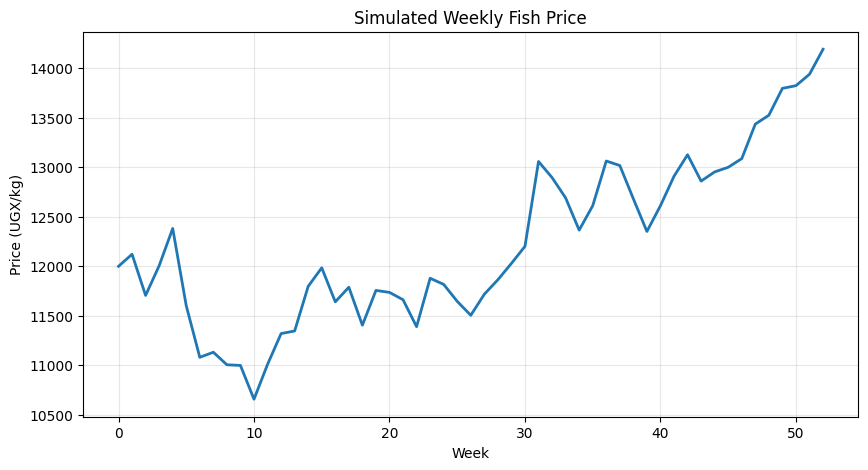

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(range(len(weekly_prices)), weekly_prices, linewidth=2)

plt.title("Simulated Weekly Fish Price")
plt.xlabel("Week")
plt.ylabel("Price (UGX/kg)")
plt.grid(True, alpha=0.3)

plt.show()

In [8]:
harvest_rate = 0.10

# Stock at the beginning of each week
starting_stock = stock_52_weeks[:-1]

weekly_harvest_tonnes = harvest_rate * starting_stock

weekly_harvest_kg = weekly_harvest_tonnes * 1000

# Use the first 52 simulated prices
prices_52_weeks = weekly_prices[1:]

# Calculate weekly revenue in UGX
weekly_revenue = weekly_harvest_kg * prices_52_weeks

print(f"Total harvest: {weekly_harvest_tonnes.sum():,.2f} tonnes")
print(f"Total annual revenue: UGX {weekly_revenue.sum():,.0f}")
print(f"Average weekly revenue: UGX {weekly_revenue.mean():,.0f}")

Total harvest: 37,362.51 tonnes
Total annual revenue: UGX 457,901,350,180
Average weekly revenue: UGX 8,805,795,196


In [9]:
weekly_results = pd.DataFrame({
    "week": np.arange(1, 53),
    "starting_stock_tonnes": starting_stock,
    "harvest_tonnes": weekly_harvest_tonnes,
    "price_ugx_per_kg": prices_52_weeks,
    "revenue_ugx": weekly_revenue
})

weekly_results.head()

,week,starting_stock_tonnes,harvest_tonnes,price_ugx_per_kg,revenue_ugx
0,1,4000.000000,400.000000,12121.886832,4.848755e+09
1,2,4560.000000,456.000000,11705.893189,5.337887e+09
2,3,5096.256000,509.625600,12006.073668,6.118602e+09
3,4,5586.259791,558.625979,12382.299554,6.917074e+09
4,5,6013.885790,601.388579,11601.885479,6.977241e+09


In [10]:
revenue_values = weekly_results["revenue_ugx"].tolist()

revenue_mean = mean(revenue_values)
revenue_median = median(revenue_values)
revenue_variance = variance(revenue_values)
revenue_sd = stdev(revenue_values)
revenue_cv = revenue_sd / revenue_mean if revenue_mean != 0 else np.nan

print(f"Mean weekly revenue: UGX {revenue_mean:,.2f}")
print(f"Median weekly revenue: UGX {revenue_median:,.2f}")
print(f"Revenue variance: {revenue_variance:,.2f} UGX²")
print(f"Revenue standard deviation: UGX {revenue_sd:,.2f}")
print(f"Revenue coefficient of variation: {revenue_cv:.4f} ({revenue_cv * 100:.2f}%)")

Mean weekly revenue: UGX 8,805,795,195.76
Median weekly revenue: UGX 8,901,551,825.24
Revenue variance: 1,524,714,502,150,011,392.00 UGX²
Revenue standard deviation: UGX 1,234,793,303.41
Revenue coefficient of variation: 0.1402 (14.02%)


Why is a variance threshold of 50,000 meaningless here? Revenue variance is measured in squared currency units, UGX². A threshold of 50,000 UGX² is extremely small relative to revenue measured in millions of UGX, and it has no universal interpretation without reference to the scale of the data. A relative measure such as CV is more useful for comparing risk across scenarios with different revenue levels.

In [11]:
print("Starting stock (tonnes):", stock_52_weeks[:5])
print("Weekly harvest (tonnes):", weekly_harvest_tonnes[:5])
print("Weekly harvest (kg):", weekly_harvest_kg[:5])
print("Weekly prices (UGX/kg):", prices_52_weeks[:5])
print("Weekly revenue (UGX):", weekly_revenue[:5])

# Check the calculation for the first week
expected_revenue = (
    weekly_harvest_tonnes[0]
    * 1000
    * prices_52_weeks[0]
)

print("First-week revenue check:", expected_revenue)

Starting stock (tonnes): [4000.         4560.         5096.256      5586.2597913  6013.88579045]
Weekly harvest (tonnes): [400.         456.         509.6256     558.62597913 601.38857905]
Weekly harvest (kg): [400000.         456000.         509625.6        558625.97912986
 601388.5790453 ]
Weekly prices (UGX/kg): [12121.8868319  11705.89318941 12006.07366773 12382.29955428
 11601.88547882]
Weekly revenue (UGX): [4.84875473e+09 5.33788729e+09 6.11860250e+09 6.91707421e+09
 6.97724142e+09]
First-week revenue check: 4848754732.760709


In [12]:
risk_assessor = RiskAssessor()

cv = risk_assessor.coefficient_of_variation(revenue_values)
risk_class = risk_assessor.classify(cv)

print(f"Revenue CV: {cv:.4f} ({cv * 100:.2f}%)")
print(f"Revenue risk class: {risk_class}")


Revenue CV: 0.1402 (14.02%)
Revenue risk class: Moderate


In [13]:
# Monte Carlo simulation settings
n_simulations = 1000
weeks = 52
harvest_rate = 0.10

# Use the same fish-stock trajectory for each price scenario
fish_model = FishStock(harvest_rate=harvest_rate)
stock_trajectory = fish_model.simulate(weeks=weeks)

# Harvest is based on the stock available at the start of each week
harvest_tonnes = harvest_rate * stock_trajectory[:-1]
harvest_kg = harvest_tonnes * 1000

# Simulate 1,000 different annual price paths
annual_revenues = []

for simulation in range(n_simulations):
    price_model = PriceModel(seed=simulation)
    simulated_prices = price_model.simulate(weeks=weeks)[1:]

    weekly_revenue_sim = harvest_kg * simulated_prices
    annual_revenue = weekly_revenue_sim.sum()

    annual_revenues.append(annual_revenue)

# Calculate Monte Carlo revenue risk measures
mean_annual_revenue = mean(annual_revenues)
median_annual_revenue = median(annual_revenues)
var_5_revenue = float(np.percentile(annual_revenues, 5))
downside_from_mean = mean_annual_revenue - var_5_revenue

print(f"Simulations: {n_simulations:,}")
print(f"Mean annual revenue: UGX {mean_annual_revenue:,.0f}")
print(f"Median annual revenue: UGX {median_annual_revenue:,.0f}")
print(f"5th-percentile annual revenue (5% VaR threshold): UGX {var_5_revenue:,.0f}")
print(f"Downside from mean to 5th percentile: UGX {downside_from_mean:,.0f}")


Simulations: 1,000
Mean annual revenue: UGX 452,706,701,074
Median annual revenue: UGX 451,089,850,381
5th-percentile annual revenue (5% VaR threshold): UGX 372,687,259,657
Downside from mean to 5th percentile: UGX 80,019,441,417


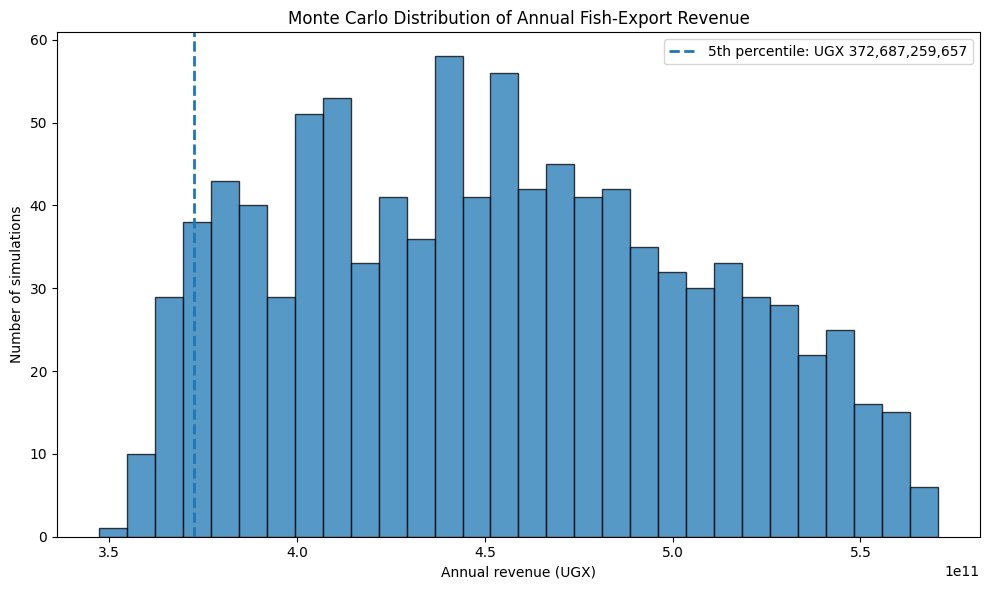

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(
    annual_revenues,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    var_5_revenue,
    linestyle="--",
    linewidth=2,
    label=f"5th percentile: UGX {var_5_revenue:,.0f}"
)

plt.xlabel("Annual revenue (UGX)")
plt.ylabel("Number of simulations")
plt.title("Monte Carlo Distribution of Annual Fish-Export Revenue")
plt.legend()
plt.tight_layout()
plt.show()


In [15]:
# Harvesting scenarios
harvest_rates = [0.05, 0.10, 0.20, 0.30]
scenario_results = []
scenario_stock = {}

# Use the same price path for all scenarios
common_prices = PriceModel(seed=42).simulate(weeks=52)[1:]

for rate in harvest_rates:
    # Simulate fish stock under this harvesting rate
    model = FishStock(harvest_rate=rate)
    stock = model.simulate(weeks=52)
    scenario_stock[rate] = stock

    # Calculate weekly harvest and revenue
    harvest_tonnes = rate * stock[:-1]
    harvest_kg = harvest_tonnes * 1000
    weekly_revenues = harvest_kg * common_prices

    # Calculate annual revenue and revenue risk
    total_revenue = weekly_revenues.sum()
    cv = risk_assessor.coefficient_of_variation(
        weekly_revenues.tolist()
    )
    risk_class = risk_assessor.classify(cv)

    scenario_results.append({
        "Harvest rate": f"{rate:.0%}",
        "Final stock (tonnes)": stock[-1],
        "Total harvest (tonnes)": harvest_tonnes.sum(),
        "Annual revenue (UGX)": total_revenue,
        "Revenue CV": cv,
        "Risk class": risk_class
    })

scenario_df = pd.DataFrame(scenario_results)
scenario_df


,Harvest rate,Final stock (tonnes),Total harvest (tonnes),Annual revenue (UGX),Revenue CV,Risk class
0,5%,8749.999997,21714.612368,2.661305e+11,0.152908,Moderate
1,10%,7499.999925,37362.508468,4.579014e+11,0.140225,Moderate
2,20%,4999.987936,50871.710791,6.230144e+11,0.095447,Low
3,30%,2503.717309,42461.018271,5.175404e+11,0.112814,Moderate


In [16]:
# Five-year closed-season comparison
years = 5
weeks_per_year = 52
total_weeks = years * weeks_per_year
baseline_harvest_rate = 0.10
closed_weeks_per_year = 8

# Use one reproducible price path for both strategies
prices_5_years = PriceModel(seed=42).simulate(
    weeks=total_weeks
)[1:]

def simulate_fishing_strategy(closed_season: bool):
    """Simulate stock and revenue over five years."""
    stock = np.zeros(total_weeks + 1)
    stock[0] = 4000.0

    harvest_tonnes = np.zeros(total_weeks)
    revenue = np.zeros(total_weeks)

    for week in range(total_weeks):
        week_of_year = week % weeks_per_year

        if closed_season and week_of_year < closed_weeks_per_year:
            rate = 0.0
        else:
            rate = baseline_harvest_rate

        current_stock = stock[week]

        natural_growth = (
            0.4
            * current_stock
            * (1 - current_stock / 10000)
        )

        harvest_tonnes[week] = rate * current_stock

        next_stock = current_stock + natural_growth - harvest_tonnes[week]
        stock[week + 1] = max(0.0, next_stock)

        revenue[week] = (
            harvest_tonnes[week] * 1000 * prices_5_years[week]
        )

    return stock, harvest_tonnes, revenue


# Continuous harvesting throughout all five years
stock_continuous, harvest_continuous, revenue_continuous = (
    simulate_fishing_strategy(closed_season=False)
)

# Eight-week closure every year
stock_closed, harvest_closed, revenue_closed = (
    simulate_fishing_strategy(closed_season=True)
)

continuous_total = revenue_continuous.sum()
closed_total = revenue_closed.sum()

comparison_df = pd.DataFrame([
    {
        "Strategy": "Continuous harvesting",
        "Final stock (tonnes)": stock_continuous[-1],
        "Total harvest (tonnes)": harvest_continuous.sum(),
        "Five-year revenue (UGX)": continuous_total
    },
    {
        "Strategy": "8-week closed season each year",
        "Final stock (tonnes)": stock_closed[-1],
        "Total harvest (tonnes)": harvest_closed.sum(),
        "Five-year revenue (UGX)": closed_total
    }
])

comparison_df


,Strategy,Final stock (tonnes),Total harvest (tonnes),Five-year revenue (UGX)
0,Continuous harvesting,7500.000000,193362.508443,2.142798e+12
1,8-week closed season each year,7500.000248,168328.518957,1.871044e+12


#### Closed-season extension: interpretation
Over the five-year simulation, continuous harvesting generated approximately UGX 2.143 trillion, compared with UGX 1.871 trillion under an eight-week closed season each year. This represents a reduction in cumulative revenue which occurs because harvesting is suspended during the closed weeks, although fish stock continues to change through natural growth. The result illustrates a potential short-term financial cost of seasonal fishing restrictions.